In [271]:
import numpy as np
from PIL import Image

PROJECTIONS = [ 
    [776.649963, -298.408539, -32.048386,  993.1581875, 132.852554,  120.885834,  -759.210876, 1982.174000, 0.744869,  0.662592,  -0.078377, 4.629312012],
    [431.503540,  586.251892,  -137.094040, 1982.053375, 23.799522,   1.964373,    -657.832764, 1725.253500, -0.321776, 0.869462,  -0.374826, 5.538025391],
    [-153.607925, 722.067139,  -127.204468, 2182.4950,   141.564346,  74.195686,   -637.070984, 1551.185125, -0.769772, 0.354474,  -0.530847, 4.737782227],
    [-823.909119, 55.557896,   -82.577644,  2498.20825,  -31.429972,  42.725830,   -777.534546, 2083.363250, -0.484634, -0.807611, -0.335998, 4.934550781],
    [-715.434998, -351.073730, -147.460815, 1978.534875, 29.429260,   -2.156084,   -779.121704, 2028.892750, 0.030776,  -0.941587, -0.335361, 4.141203125],
    [-417.221649, -700.318726, -27.361042,  1599.565000, 111.925537,  -169.101776, -752.020142, 1982.983750, 0.542421,  -0.837170, -0.070180, 3.929336426],
    [94.934860,   -668.213623, -331.895508, 769.8633125, -549.403137, -58.174614,  -342.555359, 1286.971000, 0.196630,  -0.136065, -0.970991, 3.574729736],
    [452.159027,  -658.943909, -279.703522, 883.495000,  -262.442566, 1.231108,    -751.532349, 1884.149625, 0.776201,  0.215114,  -0.592653, 4.235517090]]

SILHOUETTES = ['silh_cam00_00023_0000008550.pbm','silh_cam01_00023_0000008550.pbm','silh_cam02_00023_0000008550.pbm', 'silh_cam03_00023_0000008550.pbm', 'silh_cam04_00023_0000008550.pbm', 'silh_cam05_00023_0000008550.pbm', 'silh_cam06_00023_0000008550.pbm', 'silh_cam07_00023_0000008550.pbm']
SILHOUETTES = [np.array(Image.open('cs532_HW03/' + s)) for s in SILHOUETTES]

IMAGES = ['cam00_00023_0000008550.png','cam01_00023_0000008550.png','cam02_00023_0000008550.png', 'cam03_00023_0000008550.png', 'cam04_00023_0000008550.png', 'cam05_00023_0000008550.png', 'cam06_00023_0000008550.png', 'cam07_00023_0000008550.png']
IMAGES = [np.array(Image.open('cs532_HW03/' + i)) for i in IMAGES]

DIMS = [[-2.5, 2.5], [-3, 3], [0, 2.5]]
VOXEL_SIZE = 0.025

VOXEL_COUNTS = (np.array([(DIMS[0][1] - DIMS[0][0]), (DIMS[1][1] - DIMS[1][0]), (DIMS[2][1] - DIMS[2][0])]) / VOXEL_SIZE).astype(int)
VOXEL_COUNTS = (VOXEL_COUNTS[0], VOXEL_COUNTS[1], VOXEL_COUNTS[2])

In [272]:
print(VOXEL_COUNTS)

(200, 240, 100)


In [273]:
def create_voxel_grid(x_range, y_range, z_range, voxel_size):
    """
    Create a voxel grid with the given dimensions and voxel size.
    The voxel grid is a 3D numpy array of shape dims.
    """ 

    # Calculate the number of voxels in each dimension
    x = np.linspace(x_range[0], x_range[1], int((x_range[1]-x_range[0])/voxel_size)) + voxel_size/2
    y = np.linspace(y_range[0], y_range[1], int((y_range[1]-y_range[0])/voxel_size)) + voxel_size/2
    z = np.linspace(z_range[0], z_range[1], int((z_range[1]-z_range[0])/voxel_size)) + voxel_size/2
    
    # Create a 3D numpy array of zeros
    grid = np.meshgrid(x, y, z, indexing='ij')
    voxel_centers = np.vstack(list(map(np.ravel, grid)))    

    return voxel_centers.T, np.zeros(voxel_centers.shape[1], dtype=bool)

In [274]:
print(SILHOUETTES[0].shape)

(582, 780)


In [275]:
def is_inside_silhouette(voxel_center, projection_matrices=PROJECTIONS, silhouettes=SILHOUETTES):
    # This function should project the voxel_center to each image plane
    # using the projection matrices and check if it lies inside all silhouettes
    # Return True if inside all silhouettes, False otherwise

    assert len(projection_matrices) == len(silhouettes)

    # print(np.array(projection_matrices).shape)

    for i in range(len(silhouettes)):
        # Calculate projection voxel
        proj = np.array(projection_matrices[i]).reshape((3,4))
        
        proj_voxel = proj @ np.append(voxel_center.T, 1)
        proj_voxel = proj_voxel / proj_voxel[2] 
        proj_voxel = proj_voxel[:2]
        
        # Get Silhouette shape
        sil_shape = silhouettes[i].shape

        # Check if projection voxel is inside image bound
        if proj_voxel[1] > sil_shape[0] or proj_voxel[1] < 0 or proj_voxel[0] > sil_shape[1] or proj_voxel[0] < 0:
            return False
        
        # Check if projection voxel is inside silhouette
        if not silhouettes[i][int(proj_voxel[1]), int(proj_voxel[0])]:
            return False

    return True

In [276]:
voxel_centers, labels = create_voxel_grid(DIMS[0], DIMS[1], DIMS[2], VOXEL_SIZE)

# Check if voxel is inside all silhouettes
occupied_voxels = []
for i, voxel in enumerate(voxel_centers):
    if is_inside_silhouette(voxel):
        occupied_voxels.append(voxel)
        labels[i] = 1
        
occupied_ratio = len(occupied_voxels) / len(voxel_centers)
print("Total Occupied Voxels:", len(occupied_voxels))
print("Occupied Ratio:", occupied_ratio)

Total Occupied Voxels: 6179
Occupied Ratio: 0.0012872916666666666


In [277]:
print(voxel_centers.shape)

(4800000, 3)


In [278]:
# Identify surface voxels
labels = labels.reshape(VOXEL_COUNTS)
surface_voxels = np.zeros(VOXEL_COUNTS, dtype=bool)

# Pad labels with zeros
padding_width = ((1,1), (1,1), (1,1))
padded_labels = np.pad(labels, padding_width, mode='constant', constant_values=0)

# Check dimensions
print(padded_labels.shape)

for i in range(1, VOXEL_COUNTS[0]):
    for j in range(1, VOXEL_COUNTS[1]):
        for k in range(1, VOXEL_COUNTS[2]):
            if labels[i, j, k] == 1:
                # Take sum of cube around voxel
                sum_cube = padded_labels[i-1:i+2, j-1:j+2, k-1:k+2].sum() - 1

                if sum_cube < 26:
                    surface_voxels[i-1, j-1, k-1] = 1

print("Total Surface Voxels:", surface_voxels.sum())
print("Surface Ratio:", surface_voxels.sum() / len(voxel_centers))

(202, 242, 102)
Total Surface Voxels: 3587
Surface Ratio: 0.0007472916666666667


In [279]:
print(labels.shape)

(200, 240, 100)


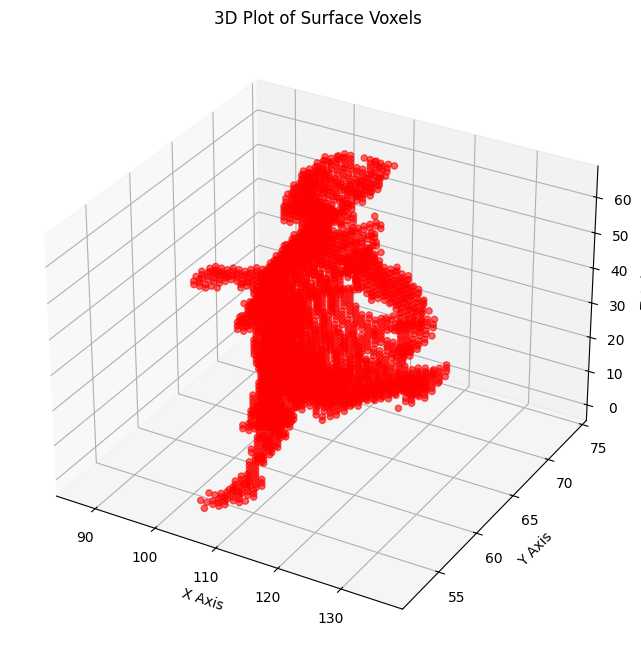

In [280]:
# %matplotlib inline
import matplotlib.pyplot as plt
# Extracting the coordinates of surface voxels for plotting
x, y, z = np.where(surface_voxels)

# Plotting
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x, y, z, alpha=0.6, c='red')

ax.set_xlabel('X Axis')
ax.set_ylabel('Y Axis')
ax.set_zlabel('Z Axis')

plt.title("3D Plot of Surface Voxels")
plt.show()

In [281]:
def get_face_centers(voxel, voxel_size):
    """
    Get the centers of voxel faces
    """
    
    x, y, z = voxel
    offset = voxel_size / 2

    # Define the 6 faces of the voxel
    faces_centers = [[x + offset, y, z], 
                    [x - offset, y, z], 
                    [x, y + offset, z], 
                    [x, y - offset, z], 
                    [x, y, z + offset], 
                    [x, y, z - offset]]

    return faces_centers

face_centers = []

for i in range(1, VOXEL_COUNTS[0] - 1):
    for j in range(1, VOXEL_COUNTS[1] - 1):
        for k in range(1, VOXEL_COUNTS[2] - 1):
            # Check if voxel is a surface voxel
            if surface_voxels[i, j, k]:  

                # Get neighboring voxels
                neighbors = [(i+1, j, k), (i-1, j, k), (i, j+1, k), 
                             (i, j-1, k), (i, j, k+1), (i, j, k-1)]

                # Get the centers of the faces of the voxel
                centers = get_face_centers((i, j, k), VOXEL_SIZE)

                for n in neighbors:
                    if not padded_labels[n]:  
                        if n == (i+1, j, k):
                            face_centers.append(centers[0])
                        elif n == (i-1, j, k):
                            face_centers.append(centers[1])
                        elif n == (i, j+1, k):
                            face_centers.append(centers[2])
                        elif n == (i, j-1, k):
                            face_centers.append(centers[3])
                        elif n == (i, j, k+1):
                            face_centers.append(centers[4])
                        elif n == (i, j, k-1):
                            face_centers.append(centers[5])

print("Total Surface Voxels:", surface_voxels.sum())
print("Total Face Centers:", len(face_centers))

Total Surface Voxels: 3587
Total Face Centers: 14060


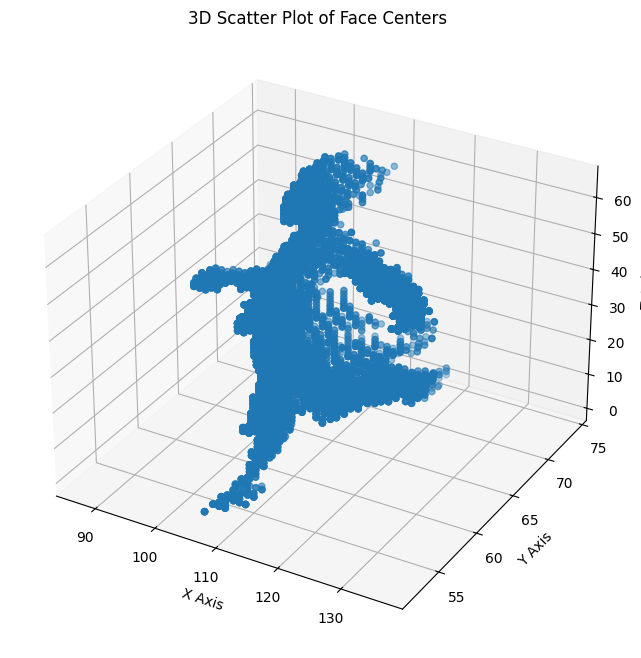

In [282]:
x = [point[0] for point in face_centers]
y = [point[1] for point in face_centers]
z = [point[2] for point in face_centers]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x, y, z)

ax.set_xlabel('X Axis')
ax.set_ylabel('Y Axis')
ax.set_zlabel('Z Axis')
plt.title("3D Scatter Plot of Face Centers")
plt.show()

In [283]:
# Determine false-color RGB for 3D points

def get_rgb_values(xs, ys, zs):
    """
    Get the RGB values for the 3D points
    """
    
    x_min, y_min, z_min = min(xs), min(ys), min(zs)
    x_max, y_max, z_max = max(xs), max(ys), max(zs)

    print(x_min)
    print(x_max)
    print(y_min)
    print(y_max)
    print(z_min)
    print(z_max)

    # Normalize the points
    rgb = np.array([[255 * (x - x_min) / (x_max - x_min), 
                    255 * (y - y_min) / (y_max - y_min), 
                    255 * (z - z_min) / (z_max - z_min)] for x, y, z in zip(xs, ys, zs)], 
                    dtype='int')
    
    print(max(rgb[:, 0]))

    return rgb

rgb = get_rgb_values(x, y, z).T

86.9875
136.0125
51.9875
74.0125
0.9875
64.0125
255


In [284]:
# Create ply file

cords = np.vstack((np.array(x), np.array(y), np.array(z)))
print(cords.shape)

def write_ply_file(vertices, rgb, filename):
    """
    Write the 3D points and their colors to a .ply file
    """
    
    output = ""
    output += "ply\n"
    output += "format ascii 1.0\n"
    output += "element vertex " + str(vertices.shape[1]) + "\n"
    output += "property float x\n"
    output += "property float y\n"
    output += "property float z\n"
    output += "property uchar red\n"
    output += "property uchar green\n"
    output += "property uchar blue\n"
    output += "element face 0\n"
    output += "end_header\n"
    for i, data in enumerate(vertices.T):
        output += " ".join([str(c) for c in data]) + " " + " ".join([str(c) for c in rgb[i]]) + '\n'

    with open(filename, 'w') as f:
        f.write(output)
        f.close()
    
    return True

write_ply_file(cords, rgb.T, "output.ply")
    


(3, 14060)


True

In [285]:
# Take the surface voxels and 
def is_inside_silhouette_w_color(voxel_center, projection_matrices=PROJECTIONS, silhouettes=SILHOUETTES, images=IMAGES):
    # This function should project the voxel_center to each image plane
    # using the projection matrices and check if it lies inside all silhouettes
    # Return True if inside all silhouettes, False otherwise

    assert len(projection_matrices) == len(silhouettes) == len(images)

    colors = []

    for i in range(len(silhouettes)):
        # Calculate projection voxel
        proj = np.array(projection_matrices[i]).reshape((3,4))
        
        proj_voxel = proj @ np.append(voxel_center.T, 1)
        proj_voxel = proj_voxel / proj_voxel[2] 
        proj_voxel = proj_voxel[:2]
        
        # Get Silhouette shape
        sil_shape = silhouettes[i].shape

        # Check if projection voxel is inside image bound
        if proj_voxel[1] > sil_shape[0] or proj_voxel[1] < 0 or proj_voxel[0] > sil_shape[1] or proj_voxel[0] < 0:
            continue
        
        # Check if projection voxel is inside silhouette
        if not silhouettes[i][int(proj_voxel[1]), int(proj_voxel[0])]:
            continue
        
        colors.append(images[i][int(proj_voxel[1])][int(proj_voxel[0])])

    # Get median RGB value for each color
    colors = np.median(colors, axis=0)
    colors = colors.astype(int)

    return colors

In [286]:
x, y, z = np.where(surface_voxels)
surface_cords = np.vstack((x, y, z)).T

# Select voxel centers at surface_cord indices
temp_voxel_centers, _ = create_voxel_grid(DIMS[0], DIMS[1], DIMS[2], VOXEL_SIZE)
temp_voxel_centers = temp_voxel_centers.reshape((VOXEL_COUNTS[0], VOXEL_COUNTS[1], VOXEL_COUNTS[2], 3))

surface_voxel_centers = []
for cord in surface_cords:
    surface_voxel_centers.append(temp_voxel_centers[cord[0], cord[1], cord[2]])

surface_voxel_centers = np.array(surface_voxel_centers)

# Get median color for each surface voxel
colors = []
for voxel in surface_voxel_centers:
    color = is_inside_silhouette_w_color(voxel)
    colors.append(color)

colors = np.array(colors)

In [287]:
# Create ply file
write_ply_file(surface_voxel_centers.T, colors, "output_color.ply")

True